In [1]:
from pathlib import Path
import sys
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "tarea_01" / "dataset").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from tarea_01.report_eda import ingredient_coverage, parse_list_column, plot_metadata, save_figure


In [2]:
dataset_path = PROJECT_ROOT / "tarea_01" / "dataset"
assets_path = PROJECT_ROOT / "tarea_01" / "informe_assets"
df = pd.read_csv(dataset_path / "item_metadata.csv")
df["ingredients"] = df["ingredients"].map(parse_list_column)
df["tags"] = df["tags"].map(parse_list_column)
df.head(2)


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,chicken lickin good pork chops,63986,500,14664,2003-06-06,"[weeknight, time-to-make, course, main-ingredi...","[105.7, 8.0, 0.0, 26.0, 5.0, 4.0, 3.0]",5,"['dredge pork chops in mixture of flour , salt...",here's and old standby i enjoy from time to ti...,"[lean pork chops, flour, salt, dry mustard, ga...",7
1,how i got my family to eat spinach spinach ca...,25775,50,37305,2002-04-22,"[60-minutes-or-less, time-to-make, course, mai...","[166.1, 16.0, 6.0, 32.0, 19.0, 26.0, 3.0]",5,"['preheat oven to 350 degrees', 'place spinach...","if spinach scares you, this is one recipe that...","[frozen chopped spinach, egg, salt, black pepp...",8


In [3]:
df["ingredients"].explode().unique()

<StringArray>
[       'lean pork chops',                  'flour',                   'salt',
            'dry mustard',          'garlic powder',                    'oil',
      'chicken rice soup', 'frozen chopped spinach',                    'egg',
           'black pepper',
 ...
     'coarse ground beef', 'unsalted chicken stock',         'sultana raisin',
     'mexican-style corn',      'whole wheat bagel',              'dry bread',
                   'ribs',               'crackers',        'pecorino cheese',
         'fresh zucchini']
Length: 3869, dtype: str

In [4]:
frecuencia_tags = df["tags"].explode().value_counts()
display(frecuencia_tags.head(10).rename("Recetas por tag"))
print(f"Tags únicos: {len(frecuencia_tags)}; tags de una sola receta: {(frecuencia_tags == 1).sum()}")


tags
preparation         7042
time-to-make        6992
course              6752
dietary             6148
main-ingredient     5638
easy                4212
occasion            4154
equipment           3797
cuisine             3134
low-in-something    3111
Name: Recetas por tag, dtype: int64

Tags únicos: 438; tags de una sola receta: 33


In [5]:
# Frecuencia documental: un ingrediente cuenta una vez por receta.
ing_counts = Counter(term for ingredients in df["ingredients"] for term in set(ingredients))
singles = sum(count == 1 for count in ing_counts.values())
under_five = sum(count < 5 for count in ing_counts.values())
print(f"Ingredientes únicos: {len(ing_counts)}")
print(f"Aparecen en una receta: {singles} ({singles / len(ing_counts):.1%})")
print(f"Aparecen en menos de cinco recetas: {under_five} ({under_five / len(ing_counts):.1%})")


Ingredientes únicos: 3869
Aparecen en una receta: 1548 (40.0%)
Aparecen en menos de cinco recetas: 2655 (68.6%)


,min_df,vocabulary,recipes,min_ingredients,recipes_with_min_ingredients,coverage_fraction,orphan_recipes,orphan_fraction,mean_ingredients,p10_ingredients,p25_ingredients,median_ingredients,p75_ingredients
0,1,3869,7047,3,6941,0.984958,0,0.000000,8.445012,4.0,6.0,8.0,11.0
1,5,1214,7047,3,6748,0.957571,9,0.001277,7.808855,4.0,5.0,7.0,10.0
2,10,713,7047,3,6574,0.932879,40,0.005676,7.337732,3.0,5.0,7.0,10.0


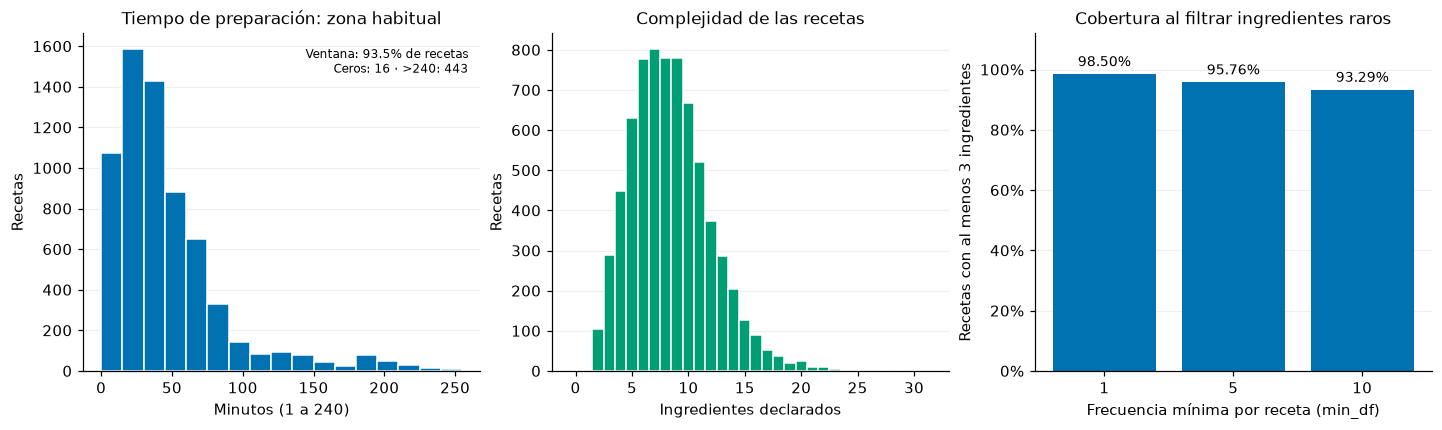

In [6]:
# Mismo cálculo utilizado por el EDA exportable y por el informe.
df_comparativa = ingredient_coverage(df["ingredients"], thresholds=(1, 5, 10))
(assets_path / "data").mkdir(parents=True, exist_ok=True)
df_comparativa.to_csv(assets_path / "data" / "ingredient_coverage.csv", index=False)
display(df_comparativa)
fig = plot_metadata(df, df_comparativa)
save_figure(fig, assets_path / "eda_metadata")
plt.show()


In [7]:
display(df_comparativa[[
    "min_df", "vocabulary", "p10_ingredients", "p25_ingredients",
    "median_ingredients", "p75_ingredients",
]])
minutes = pd.to_numeric(df["minutes"], errors="coerce")
print(f"Minutos: mediana {minutes.median():g}, P99 {minutes.quantile(.99):g}, máximo {minutes.max():g}")
print(f"Ceros: {minutes.eq(0).sum()}; mayores a un día: {minutes.gt(1440).sum()}")
display(df.loc[minutes.eq(0) | minutes.gt(1440), ["id", "name", "minutes"]]
        .sort_values("minutes", ascending=False).head(10))


,min_df,vocabulary,p10_ingredients,p25_ingredients,median_ingredients,p75_ingredients
0,1,3869,4.0,6.0,8.0,11.0
1,5,1214,4.0,5.0,7.0,10.0
2,10,713,3.0,5.0,7.0,10.0


Minutos: mediana 35, P99 858.6, máximo 2.14748e+09
Ceros: 16; mayores a un día: 54


,id,name,minutes
4563,261647,no bake granola balls,2147483647
5598,105417,ruth s homemade vanilla extract,86405
4749,340621,our daily bread in a crock weekly make and b...,20190
1854,103136,cranberry liqueur,17300
3750,90487,kittencal s easy refrigerator kosher garlic di...,10095
5705,102612,scents for the holidays,10085
6250,241141,sunshine dill pickles,5775
5959,13750,sourdough bread starter,5760
176,121686,andreas viestad s vodka marinated sirloin,4395
1983,9458,crisp cucumber freezer pickles,4350


## Decisiones de representación y límites

La cobertura compara el vocabulario completo con filtros por frecuencia documental. Reducir ingredientes raros simplifica la representación, pero aumenta las recetas sin suficientes señales; por eso se muestran cobertura, recetas huérfanas y cuantiles, no solo el tamaño del vocabulario. Estos resultados describen viabilidad: la calidad de Content-Based debe medirse con el protocolo común de validación.

El histograma de minutos muestra explícitamente la ventana de 1 a 240 minutos e indica cuántas recetas quedan fuera. Los ceros y valores extremos requieren revisar su significado antes de usar tiempo como atributo numérico. No se eliminan automáticamente recetas largas: pueden corresponder a fermentación o cocción lenta. El máximo cercano al límite de un entero de 32 bits es sospechoso y no debe interpretarse como un tiempo de preparación normal.

Los ingredientes y tags tienen cobertura completa en este catálogo, mientras que las descripciones pueden faltar. La figura y `ingredient_coverage.csv` usan la misma función que el informe; el listado `metadata_minutes_review.csv` mantiene trazabilidad de los casos a revisar.
